In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, confusion_matrix

# 1. Đọc dữ liệu sạch
df = pd.read_csv('../data/processed/hotel_bookings_clean.csv')

# 2. SỬA LỖI MIXED TYPES: Ép tất cả cột dạng object về string thuần túy
# Khai báo trực tiếp các cột hạng mục của nhóm
cat_cols = [
    'hotel', 'arrival_date_month', 'meal', 'country', 
    'market_segment', 'distribution_channel', 
    'reserved_room_type', 'assigned_room_type', 
    'deposit_type', 'customer_type'
]

# Đảm bảo tất cả các cột này đều được ép kiểu chuỗi (string) để tránh lỗi format
for col in cat_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

# 3. Tách biến đặc trưng (X) và nhãn mục tiêu (y)
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

# 4. Chia tập Train / Test theo tỷ lệ 80/20 phân tầng (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tập huấn luyện (Train): {X_train.shape[0]:,} dòng")
print(f"Tập kiểm thử (Test): {X_test.shape[0]:,} dòng")

Tập huấn luyện (Train): 95,366 dòng
Tập kiểm thử (Test): 23,842 dòng


In [15]:
# Phân loại cột số và cột hạng mục
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Preprocessor: Chuẩn hóa cột số và Mã hóa One-Hot cột hạng mục
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

print("Đã khởi tạo Preprocessor pipeline thành công!")

Đã khởi tạo Preprocessor pipeline thành công!


/tmp/ipykernel_14153/2804102073.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns.tolist()


In [16]:
# 1. Baseline Model (Đoán lớp đa số)
baseline = Pipeline([
    ('prep', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])
baseline.fit(X_train, y_train)
baseline_acc = baseline.score(X_test, y_test)
print(f"--- Mô hình Baseline (Đoán đa số) Accuracy: {baseline_acc:.4f} ---")

# 2. Danh sách 4 thuật toán huấn luyện
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

# 3. Huấn luyện và Đánh giá ROC-AUC
results = []
for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])
    
    # Huấn luyện
    pipe.fit(X_train, y_train)
    
    # Dự đoán xác suất
    y_pred_proba = pipe.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    
    results.append({'Model': name, 'ROC-AUC': auc_score, 'Pipeline': pipe})
    print(f"Mô hình {name:20s} | ROC-AUC Test: {auc_score:.4f}")

# Chuyển kết quả thành DataFrame
df_results = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)

--- Mô hình Baseline (Đoán đa số) Accuracy: 0.6292 ---
Mô hình Logistic Regression  | ROC-AUC Test: 0.8962
Mô hình Decision Tree        | ROC-AUC Test: 0.8542
Mô hình Random Forest        | ROC-AUC Test: 0.9591
Mô hình Gradient Boosting    | ROC-AUC Test: 0.9268


In [17]:
# 1. Đọc lại dữ liệu gốc có chứa reservation_status
df_raw = pd.read_csv('../data/raw/hotel_bookings.csv')

# 2. Điền ô trống bằng 0 và ép tất cả cột dạng object về string đồng nhất
df_raw = df_raw.fillna(0)
for col in df_raw.select_dtypes(include=['object']).columns:
    df_raw[col] = df_raw[col].astype(str)

# 3. Tạo tập dữ liệu thử nghiệm rò rỉ nhãn
X_leak = df_raw.drop(columns=['is_canceled'])
y_leak = df_raw['is_canceled']

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_leak, y_leak, test_size=0.2, random_state=42, stratify=y_leak
)

num_l = X_leak.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_l = X_leak.select_dtypes(include=['object']).columns.tolist()

prep_leak = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_l),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_l)
])

leak_model = Pipeline([
    ('prep', prep_leak),
    ('model', DecisionTreeClassifier(random_state=42))
])

# 4. Huấn luyện mô hình và đo điểm ROC-AUC
leak_model.fit(X_train_l, y_train_l)
leak_auc = roc_auc_score(y_test_l, leak_model.predict_proba(X_test_l)[:, 1])

best_clean_auc = df_results.iloc[0]['ROC-AUC']

print(f"ROC-AUC KHI BỊ RÒ RỈ NHÃN (Có reservation_status): {leak_auc:.4f}")
print(f"ROC-AUC KHI ĐÃ SẠCH (Không rò rỉ nhãn):              {best_clean_auc:.4f}")
print(f"-> Điểm số tăng giả tạo do rò rỉ nhãn:                +{(leak_auc - best_clean_auc)*100:.2f}%")

/tmp/ipykernel_14153/4204171834.py:5: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df_raw = df_raw.fillna(0)
/tmp/ipykernel_14153/4204171834.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_raw.select_dtypes(include=['object']).columns:
/tmp/ipykernel_14153/4204171834.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is de

ROC-AUC KHI BỊ RÒ RỈ NHÃN (Có reservation_status): 1.0000
ROC-AUC KHI ĐÃ SẠCH (Không rò rỉ nhãn):              0.9591
-> Điểm số tăng giả tạo do rò rỉ nhãn:                +4.09%


--- TỐI ƯU HÓA MA TRẬN CHI PHÍ OVERBOOKING ---
Ngưỡng quyết định tối ưu theo tiền tệ: 0.60
Tổng chi phí tổn thất tối thiểu:      $161,500.00


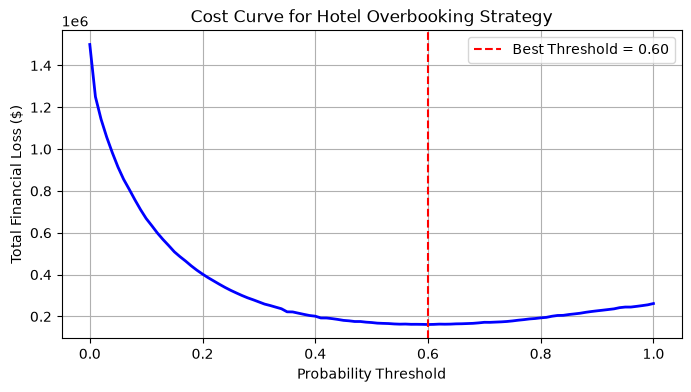

In [18]:
# Lấy mô hình tốt nhất từ Cell 3 (Thường là Random Forest hoặc Gradient Boosting)
best_pipeline = df_results.iloc[0]['Pipeline']
y_probs = best_pipeline.predict_proba(X_test)[:, 1]

# Giả định chi phí tài chính cho khách sạn:
# C_overbooking = 100$ (Đoán "Sẽ hủy" -> Bán lố phòng -> Khách tới không có phòng ở -> Đền bù tiền & uy tín)
# C_empty       = 50$  (Đoán "Không hủy" -> Khách hủy thật -> Phòng trống lãng phí doanh thu)
C_overbooking = 100
C_empty = 50

thresholds = np.linspace(0, 1, 101)
cost_list = []

for th in thresholds:
    y_pred_th = (y_probs >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_th).ravel()
    
    # FP (False Positive): Đoán hủy nhưng khách không hủy -> Bán vượt lố -> Mất C_overbooking
    # FN (False Negative): Đoán không hủy nhưng khách hủy -> Phòng trống -> Mất C_empty
    total_cost = (fp * C_overbooking) + (fn * C_empty)
    cost_list.append(total_cost)

# Tìm ngưỡng có tổng chi phí thiệt hại thấp nhất
min_cost_idx = np.argmin(cost_list)
best_threshold = thresholds[min_cost_idx]
min_cost = cost_list[min_cost_idx]

print(f"--- TỐI ƯU HÓA MA TRẬN CHI PHÍ OVERBOOKING ---")
print(f"Ngưỡng quyết định tối ưu theo tiền tệ: {best_threshold:.2f}")
print(f"Tổng chi phí tổn thất tối thiểu:      ${min_cost:,.2f}")

# Vẽ đồ thị đường cong chi phí theo Ngưỡng
plt.figure(figsize=(8, 4))
plt.plot(thresholds, cost_list, color='b', linewidth=2)
plt.axvline(best_threshold, color='r', linestyle='--', label=f'Best Threshold = {best_threshold:.2f}')
plt.title('Cost Curve for Hotel Overbooking Strategy')
plt.xlabel('Probability Threshold')
plt.ylabel('Total Financial Loss ($)')
plt.legend()
plt.grid(True)
plt.show()

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("\n--- THỰC HIỆN HỌ BÀI TOÁN PHỤ: PHÂN CỤM K-MEANS HÀNH VI KHÁCH HÀNG ---")

# 1. Chọn các đặc trưng hành vi đặt phòng
cluster_cols = ['lead_time', 'adr', 'stays_in_week_nights', 'stays_in_weekend_nights', 'total_of_special_requests']
X_cluster = df[cluster_cols].copy()

# 2. Chuẩn hóa dữ liệu K-Means (Bắt buộc để tránh lệch thang đo)
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

# 3. Huấn luyện K-Means với k=3 cụm hành vi
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_label'] = kmeans.fit_predict(X_cluster_scaled)

# 4. Đánh giá chất lượng cụm bằng Silhouette Score trên mẫu ngẫu nhiên 10,000 dòng
sil_score = silhouette_score(X_cluster_scaled[:10000], df['cluster_label'][:10000])
print(f"Silhouette Score cho 3 cụm hành vi: {sil_score:.4f}")

# 5. Phân tích hồ sơ từng cụm hành vi và tỷ lệ hủy tương ứng
cluster_profile = df.groupby('cluster_label').agg({
    'lead_time': 'mean',
    'adr': 'mean',
    'stays_in_week_nights': 'mean',
    'total_of_special_requests': 'mean',
    'is_canceled': ['count', 'mean']
}).reset_index()

cluster_profile.columns = ['Cụm', 'Lead Time Trung Bình', 'ADR Trung Bình', 'Số Đêm Tuần Trung Bình', 'Yêu Cầu Đặc Biệt', 'Số Lượng Đơn', 'Tỷ Lệ Hủy']
print("\n--- HỒ SƠ CÁC PHÂN KHÚC KHÁCH HÀNG ---")
print(cluster_profile.to_string(index=False))


--- THỰC HIỆN HỌ BÀI TOÁN PHỤ: PHÂN CỤM K-MEANS HÀNH VI KHÁCH HÀNG ---
Silhouette Score cho 3 cụm hành vi: 0.2425

--- HỒ SƠ CÁC PHÂN KHÚC KHÁCH HÀNG ---
 Cụm  Lead Time Trung Bình  ADR Trung Bình  Số Đêm Tuần Trung Bình  Yêu Cầu Đặc Biệt  Số Lượng Đơn  Tỷ Lệ Hủy
   0            111.496098       84.469669                1.856861          0.176342         68940   0.427357
   1            144.891191      100.576757                5.613426          0.540695         17324   0.378204
   2             67.204802      139.163766                2.205652          1.414673         32944   0.248422


<Figure size 600x600 with 0 Axes>

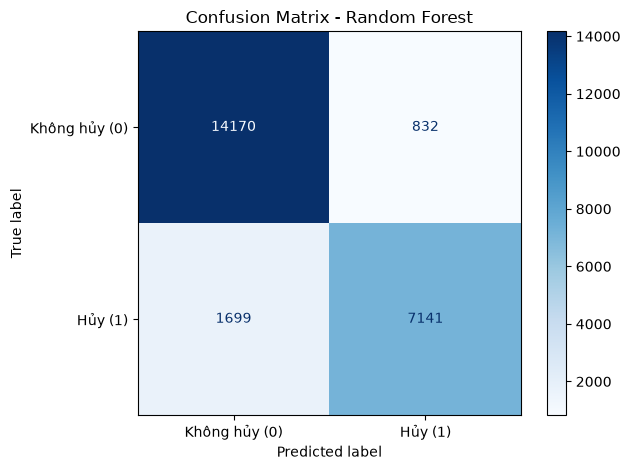

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Lấy pipeline đã huấn luyện có kèm theo preprocessor (pipeline này tự động xử lý cột chữ 'City Hotel')
# Dựa trên file notebook 03 của nhóm, ta lấy pipeline từ danh sách kết quả:
best_pipe = [r['Pipeline'] for r in results if r['Model'] == 'Random Forest'][0]

# 2. Dự đoán trực tiếp bằng pipeline trên X_test thô (pipeline sẽ tự động One-Hot Encode các cột chữ)
y_pred = best_pipe.predict(X_test)

# 3. Vẽ ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Không hủy (0)', 'Hủy (1)'])
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title('Confusion Matrix - Random Forest')
plt.tight_layout()
plt.show()